In [1]:
!pip install blitz-bayesian-pytorch

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.4/48.4 kB 343.0 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 40.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 823.6/823.6 kB 46.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 MB 28.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 731.7/731.7 MB 1.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.6/410.6 MB 3.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.6/121.6 MB 9.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.5/56.5 MB 11.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 124.2/124.2 MB 9.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 196.0/196.0 MB 5.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.0/166.0 MB 2.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.1/99.1 kB 15.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
import matplotlib.pyplot as plt
import math
import pickle
import numpy as np
import torch
import torch.nn as nn
import pandas as pd
import seaborn as sns
import torch.optim as optim
import torch.nn.functional as F
import torch.nn as nn
import json
from blitz.modules import BayesianLinear
from blitz.utils import variational_estimator
from torch.utils.data import TensorDataset, DataLoader
from matplotlib.pyplot import scatter, figure
from scipy import stats
from numpy.ma.core import outer
from sys import stderr

In [4]:
start = -7
end = 7
n = 300
batch_size = 16


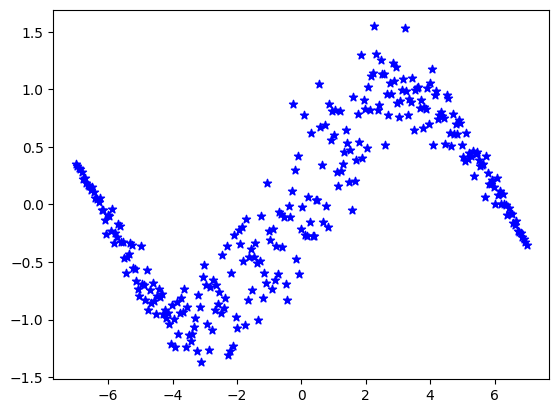

In [5]:
def sample_dataset(start, end, n):
    np.random.seed(0)
    x = np.linspace(start, end, n)
    sample_mean = [math.sin(i/2) for i in x]

    sample_var = [abs((abs(start)+abs(end))/2 - abs(i))/16 for i in x]
    y = stats.norm(sample_mean, sample_var).rvs(random_state=0)
    return x, y

x_train, y_train = sample_dataset(start, end, n)
scatter(x_train, y_train, c="blue", marker="*")

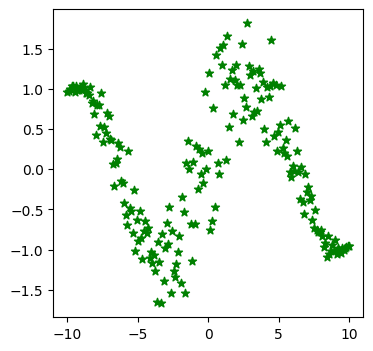

In [6]:
figure(figsize=(4, 4))
# Not exactely the same distribution, but works for now
x_test, y_test = sample_dataset(-10, 10, 200)
scatter(x_test, y_test, c="green", marker="*")

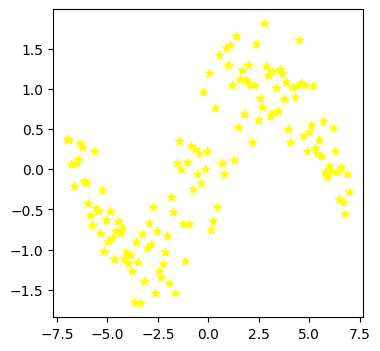

In [7]:
#Plotting In Training Distribution Data Points in the Test Set
# Filter the data to retain only the desired ranges
mask =  (x_test >= -7) &  (x_test <= 7) # Select the ranges -10 to -7 and 7 to 10
x_test_idd = x_test[mask]
y_test_idd = y_test[mask]

plt.figure(figsize=(4, 4))
plt.scatter(x_test_idd, y_test_idd, c="yellow", marker="*")

plt.show()


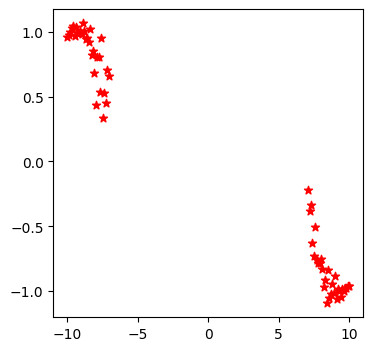

In [8]:
#Plotting Out of Training Distribution Data Points in the Test Set
# Filter the data to retain only the desired ranges
mask = (x_test >= -10) & (x_test < -7) | (x_test > 7) & (x_test <= 10) # Select the ranges -10 to -7 and 7 to 10
x_test_oodd = x_test[mask]
y_test_oodd = y_test[mask]

plt.figure(figsize=(4, 4))
plt.scatter(x_test_oodd, y_test_oodd, c="red", marker="*")

plt.show()


In [9]:

# Train
tensor_x = torch.Tensor(x_train).unsqueeze(1)
tensor_y = torch.Tensor(y_train).unsqueeze(1)
train_dataset = TensorDataset(tensor_x, tensor_y)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

#Test for OODD (Out of Data Distribution)
tensor_x_test_oodd = torch.Tensor(x_test_oodd).unsqueeze(1)
tensor_y_test_oodd = torch.Tensor(y_test_oodd).unsqueeze(1)
test_dataset_oodd = TensorDataset(tensor_x_test_oodd, tensor_y_test_oodd)
test_loader_oodd = DataLoader(test_dataset_oodd, batch_size=batch_size, shuffle=True)

#Test for IDD (In Data Distribution)
tensor_x_test_idd = torch.Tensor(x_test_idd).unsqueeze(1)
tensor_y_test_idd = torch.Tensor(y_test_idd).unsqueeze(1)
test_dataset_idd = TensorDataset(tensor_x_test_idd, tensor_y_test_idd)
test_loader_idd = DataLoader(test_dataset_idd, batch_size=batch_size, shuffle=True)

# Test
tensor_x_test = torch.Tensor(x_test).unsqueeze(1)
tensor_y_test = torch.Tensor(y_test).unsqueeze(1)
test_dataset = TensorDataset(tensor_x_test, tensor_y_test)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=True)

In [13]:
@variational_estimator
class BayesianNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        hidden_size = 29
        self.blinear1 = BayesianLinear(1, hidden_size, prior_sigma_1=1)
        self.blinear2 = BayesianLinear(hidden_size, hidden_size, prior_sigma_1=1)
        self.blinear3 = BayesianLinear(hidden_size, 1, prior_sigma_1=1)

    def forward(self, x):
        x_ = torch.relu(self.blinear1(x))
        x_ = torch.relu(self.blinear2(x_))
        print(x_)
        return self.blinear3(x_)

In [14]:
net=BayesianNetwork()
net

BayesianNetwork(
  (blinear1): BayesianLinear(
    (weight_sampler): TrainableRandomDistribution()
    (bias_sampler): TrainableRandomDistribution()
    (weight_prior_dist): PriorWeightDistribution()
    (bias_prior_dist): PriorWeightDistribution()
  )
  (blinear2): BayesianLinear(
    (weight_sampler): TrainableRandomDistribution()
    (bias_sampler): TrainableRandomDistribution()
    (weight_prior_dist): PriorWeightDistribution()
    (bias_prior_dist): PriorWeightDistribution()
  )
  (blinear3): BayesianLinear(
    (weight_sampler): TrainableRandomDistribution()
    (bias_sampler): TrainableRandomDistribution()
    (weight_prior_dist): PriorWeightDistribution()
    (bias_prior_dist): PriorWeightDistribution()
  )
)

In [ ]:

def plot_with_confidence_interval(model, tensor_x_test, tensor_y_test, x_test,y_test,color,start, end):
    samples = 500
    preds = [model(tensor_x_test) for i in range(samples)]
    preds = torch.stack(preds)
    means = preds.mean(axis=0).detach().numpy()
    stds =  preds.std(axis=0).detach().numpy()
    mu = means
    sigma = stds
    # Calculate the 95% confidence interval
    lower_bound = mu - 2 * sigma
    upper_bound = mu + 2 * sigma

    # Count the data points within the confidence interval
    count_within_ci = np.sum((tensor_y_test.numpy() >= lower_bound) & (tensor_y_test.numpy() <= upper_bound))
    percentage_count_within_ci = (count_within_ci / tensor_y_test.shape[0]) * 100
    print(f'Number of data points within the 95% confidence interval: {count_within_ci}')
    print(f'Percentage of data points within the 95% confidence interval: {percentage_count_within_ci}')

    # ~ 95% conf. interval (see https://en.wikipedia.org/wiki/1.96)
    y_vals = [mu, mu + 2 * sigma, mu - 2 * sigma]
    dfs = []

    # Create DF from predictions
    for i in range(3):
        data = {
            "x": list(tensor_x_test.squeeze().numpy()),
            "y": list(y_vals[i].squeeze())
        }
        temp = pd.DataFrame.from_dict(data)
        dfs.append(temp)
    df = pd.concat(dfs).reset_index()

    # Plot predictions with confidence
    sns.set(rc={'figure.figsize': (4, 4)})
    sns_plot = sns.lineplot(data=df, x="x", y="y")

    # Highlight training range
    plt.axvline(x=start)
    plt.axvline(x=end)

    # Plot test data on top
    scatter(x_test, y_test, c=color, marker="*", alpha=1.0)
    plt.show()
    return percentage_count_within_ci


In [ ]:
def train_and_evaluate_net(net, train_loader, test_loader, tensor_x_test, tensor_y_test,  x_test, y_test, color, test_dataset,num_epochs=150, learning_rate=0.001):
    # Define loss and optimizer
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    criterion = torch.nn.MSELoss()
    optimizer = optim.Adam(net.parameters(), lr=learning_rate)
    net.train()
    net.to(device)

    for epoch in range(num_epochs):
        # Train loop
        for batch in train_loader:
            x, y = batch[0].to(device), batch[1].to(device)
            optimizer.zero_grad()
            loss = net.sample_elbo(inputs=x,
                           labels=y,
                           criterion=criterion,
                           sample_nbr=1,
                           complexity_cost_weight=0.01/len(train_dataset))
            loss.backward()
            optimizer.step()

        if epoch % 10 == 0:
            all_test_losses = []

            # Test loop
            for batch in test_loader:
                x, y = batch[0].to(device), batch[1].to(device)
                loss = net.sample_elbo(inputs=x,
                           labels=y,
                           criterion=criterion,
                           sample_nbr=3,
                           complexity_cost_weight=0.01/len(test_dataset))
                all_test_losses.append(loss.item())
            test_loss = sum(all_test_losses) / len(all_test_losses)

    percentage_count_within_ci=plot_with_confidence_interval(net, tensor_x_test, tensor_y_test,x_test,y_test,color,start, end)
    return loss, test_loss,net,percentage_count_within_ci

def Neural_Network(net,train_loader,test_loader,tensor_x_test,tensor_y_test, x_test,y_test,color,tst_dtast):
    train_loss, test_loss,net,percentage_count_within_ci = train_and_evaluate_net(net, train_loader, test_loader,tensor_x_test,tensor_y_test, x_test,y_test,color,tst_dtast)
    return train_loss, test_loss,net,percentage_count_within_ci



In [ ]:

# Example JSON string
json_str = '''
{
  "test_loaders": ["test_loader", "test_loader_oodd", "test_loader_idd"],
  "test_tensors_x":["tensor_x_test","tensor_x_test_oodd","tensor_x_test_idd"],
  "test_tensors_y":["tensor_y_test","tensor_y_test_oodd","tensor_y_test_idd"],
  "test_datasets":["test_dataset","test_dataset_oodd","test_dataset_idd"],
  "color":["green","red","yellow"],
  "testset_x":["x_test","x_test_oodd","x_test_idd"],
  "testset_y":["y_test","y_test_oodd","y_test_idd"],
  "output_dirs": ["pickled_models_", "pickled_models_oodd_", "pickled_models_idd_"],
  "error_metrics":["em","em_oodd","em_idd"]
}
'''

# Parse JSON
data = json.loads(json_str)

# Map string names to actual variables
test_loader_vars = {
    "test_loader": test_loader,
    "test_loader_oodd": test_loader_oodd,
    "test_loader_idd": test_loader_idd
}
tensor_x_mapping = {
    "tensor_x_test": tensor_x_test,
    "tensor_x_test_oodd": tensor_x_test_oodd,
    "tensor_x_test_idd": tensor_x_test_idd
}

tensor_y_mapping = {
    "tensor_y_test": tensor_y_test,
    "tensor_y_test_oodd": tensor_y_test_oodd,
    "tensor_y_test_idd": tensor_y_test_idd
}
testset_x_mapping = {
    "x_test": x_test,
    "x_test_oodd": x_test_oodd,
    "x_test_idd": x_test_idd
}

# Mapping from string names to actual variables for testset_y
testset_y_mapping = {
    "y_test": y_test,
    "y_test_oodd": y_test_oodd,
    "y_test_idd": y_test_idd
}
test_datasets_mapping = {
    "test_dataset": test_dataset,
    "test_dataset_oodd": test_dataset_oodd,
    "test_dataset_idd": test_dataset_idd
}
# Access corresponding values using a loop
test_loaders = data["test_loaders"]
test_tensors_x=data["test_tensors_x"]
test_tensors_y=data["test_tensors_y"]
test_datasets=data["test_datasets"]
color=data["color"]
testset_x=data["testset_x"]
testset_y=data["testset_y"]
output_dirs = data["output_dirs"]
error_mets=data["error_metrics"]



Number of data points within the 95% confidence interval: 22
Percentage of data points within the 95% confidence interval: 11.0


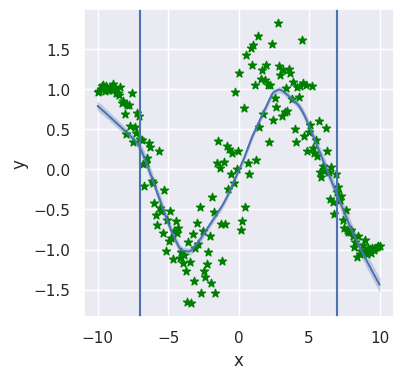

Number of data points within the 95% confidence interval: 27
Percentage of data points within the 95% confidence interval: 13.5


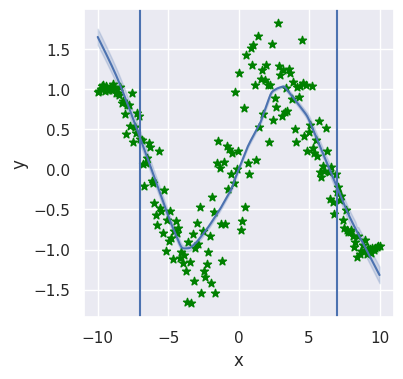

Number of data points within the 95% confidence interval: 25
Percentage of data points within the 95% confidence interval: 12.5


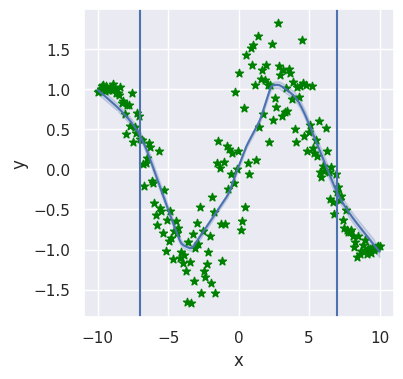

Number of data points within the 95% confidence interval: 31
Percentage of data points within the 95% confidence interval: 15.5


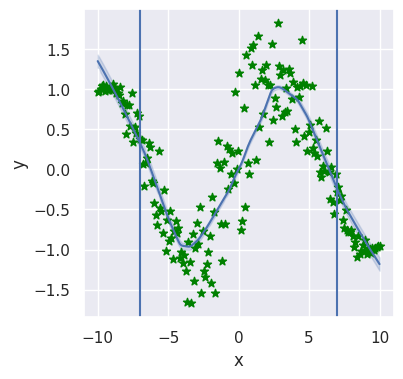

Number of data points within the 95% confidence interval: 27
Percentage of data points within the 95% confidence interval: 13.5


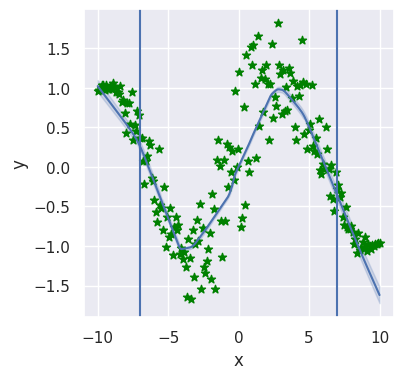

Number of data points within the 95% confidence interval: 30
Percentage of data points within the 95% confidence interval: 15.0


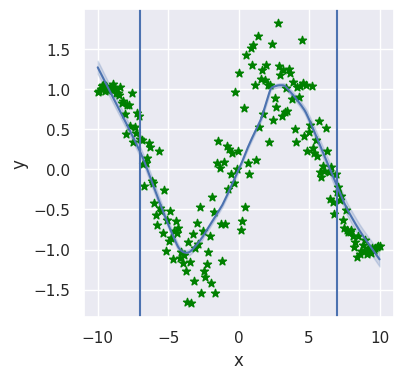

Number of data points within the 95% confidence interval: 33
Percentage of data points within the 95% confidence interval: 16.5


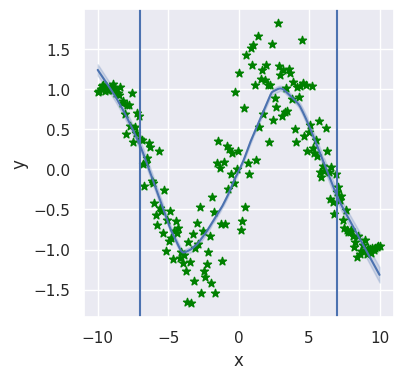

Number of data points within the 95% confidence interval: 23
Percentage of data points within the 95% confidence interval: 11.5


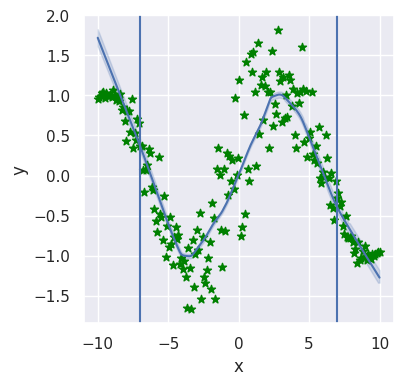

Number of data points within the 95% confidence interval: 25
Percentage of data points within the 95% confidence interval: 12.5


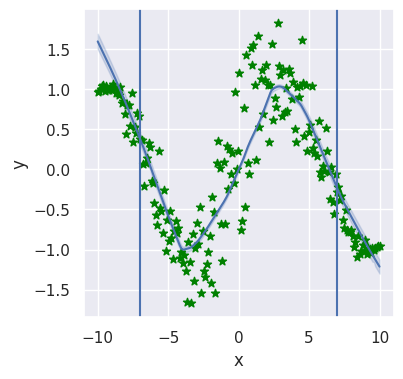

Number of data points within the 95% confidence interval: 25
Percentage of data points within the 95% confidence interval: 12.5


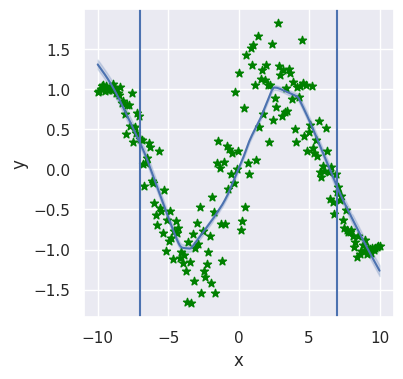

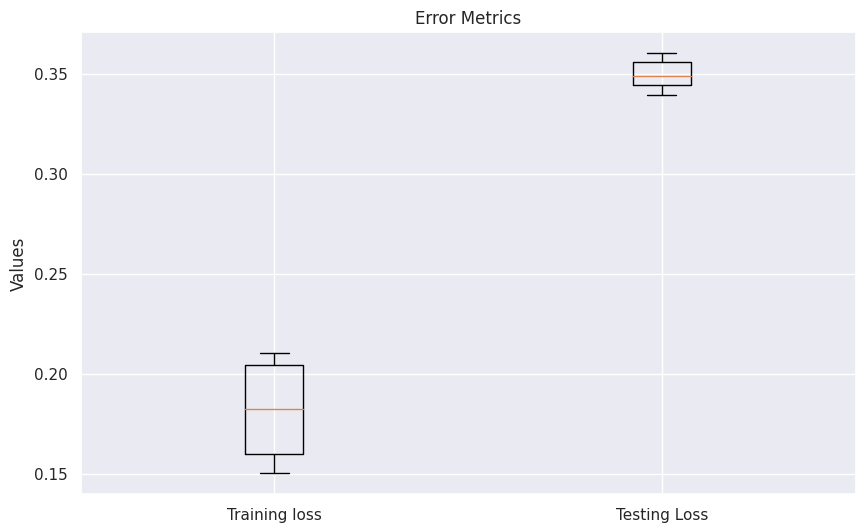

    Training Loss  Testing Loss  % of points in Confidence Interval
1        0.210363      0.360595                                11.0
2        0.208255      0.355934                                13.5
3        0.203100      0.355384                                12.5
4        0.181661      0.343879                                15.5
5        0.157081      0.346928                                13.5
6        0.205058      0.350540                                15.0
7        0.150354      0.340598                                16.5
8        0.158363      0.359108                                11.5
9        0.163035      0.346296                                12.5
10       0.183182      0.339389                                12.5
Mean of Gausiann Training Loss of 10 runs  0.18204502314329146
Standard Deviation of Gausiann Training Loss of 10 runs  0.022389630074070962
Mean of Gausiann Testing Loss of 10 runs  0.3498650866059157
Standard Deviation of Gausiann Testing Loss of 10 

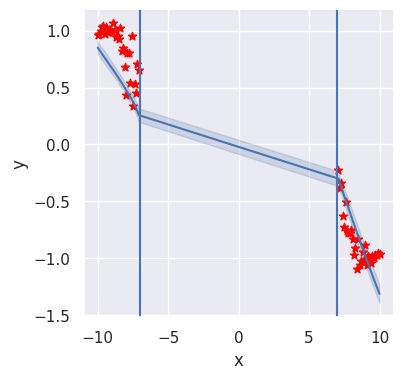

Number of data points within the 95% confidence interval: 18
Percentage of data points within the 95% confidence interval: 30.0


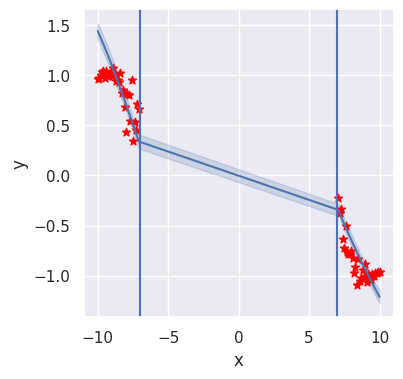

Number of data points within the 95% confidence interval: 19
Percentage of data points within the 95% confidence interval: 31.666666666666664


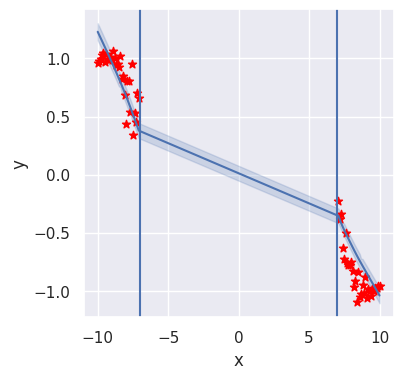

Number of data points within the 95% confidence interval: 16
Percentage of data points within the 95% confidence interval: 26.666666666666668


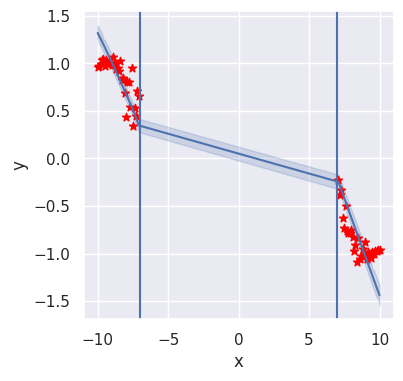

Number of data points within the 95% confidence interval: 11
Percentage of data points within the 95% confidence interval: 18.333333333333332


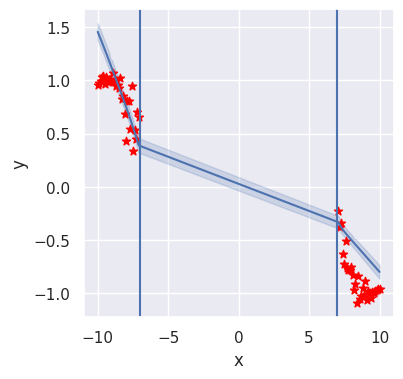

Number of data points within the 95% confidence interval: 17
Percentage of data points within the 95% confidence interval: 28.333333333333332


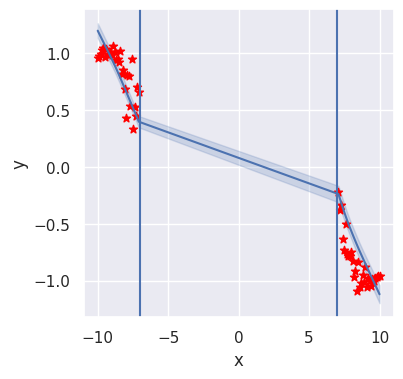

Number of data points within the 95% confidence interval: 7
Percentage of data points within the 95% confidence interval: 11.666666666666666


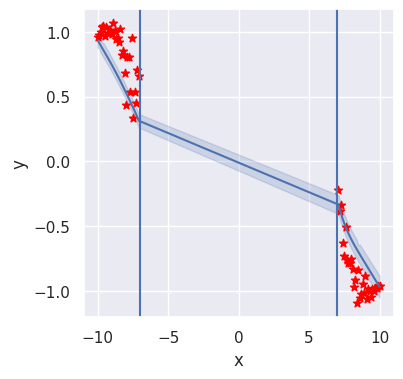

Number of data points within the 95% confidence interval: 19
Percentage of data points within the 95% confidence interval: 31.666666666666664


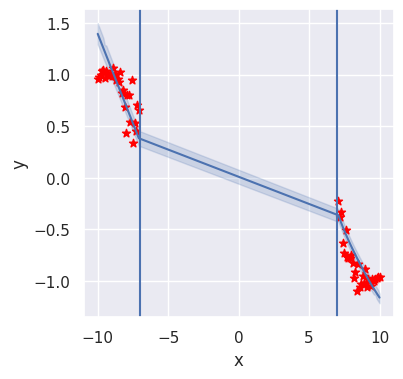

Number of data points within the 95% confidence interval: 6
Percentage of data points within the 95% confidence interval: 10.0


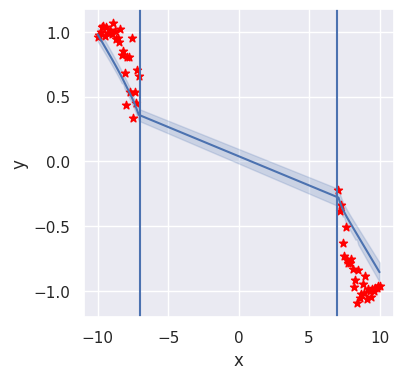

Number of data points within the 95% confidence interval: 8
Percentage of data points within the 95% confidence interval: 13.333333333333334


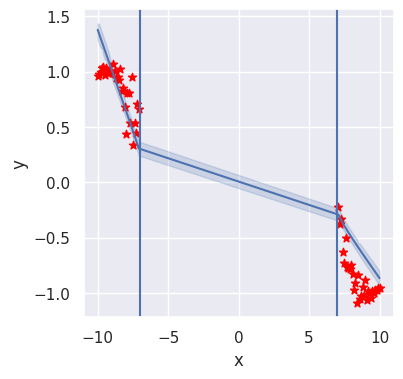

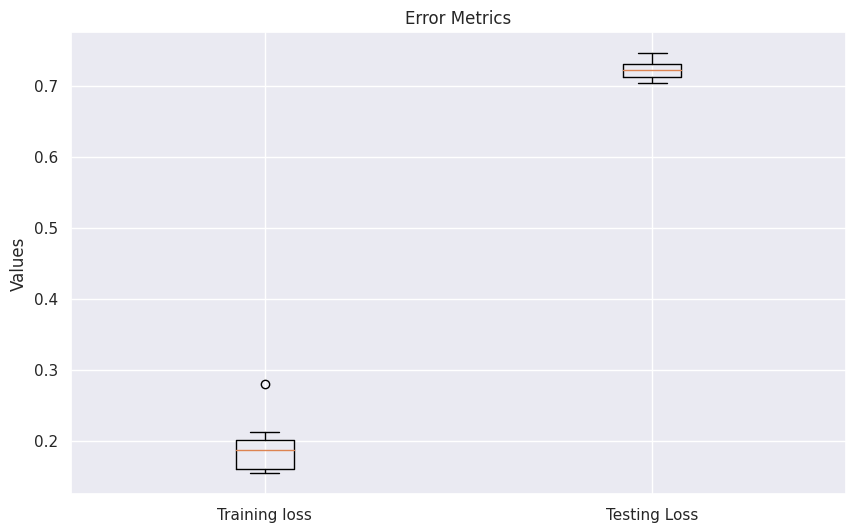

    Training Loss  Testing Loss  % of points in Confidence Interval
1        0.155666      0.727307                           16.666667
2        0.154578      0.712124                           30.000000
3        0.169754      0.712972                           31.666667
4        0.197769      0.730757                           26.666667
5        0.212024      0.746608                           18.333333
6        0.279666      0.703939                           28.333333
7        0.201222      0.718189                           11.666667
8        0.194476      0.703588                           31.666667
9        0.177707      0.735098                           10.000000
10       0.156980      0.729130                           13.333333
Mean of Gausiann Training Loss of 10 runs  0.18998409509658815
Standard Deviation of Gausiann Training Loss of 10 runs  0.03579975080042395
Mean of Gausiann Testing Loss of 10 runs  0.7219710797071457
Standard Deviation of Gausiann Testing Loss of 10 r

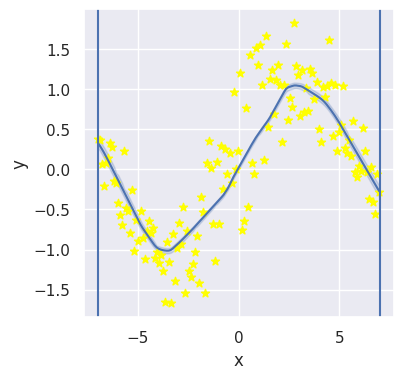

Number of data points within the 95% confidence interval: 10
Percentage of data points within the 95% confidence interval: 7.142857142857142


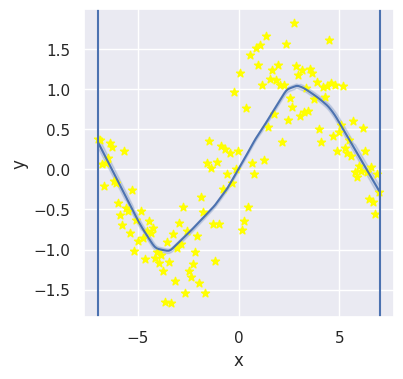

Number of data points within the 95% confidence interval: 13
Percentage of data points within the 95% confidence interval: 9.285714285714286


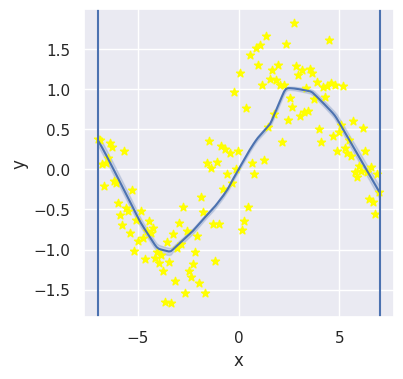

Number of data points within the 95% confidence interval: 12
Percentage of data points within the 95% confidence interval: 8.571428571428571


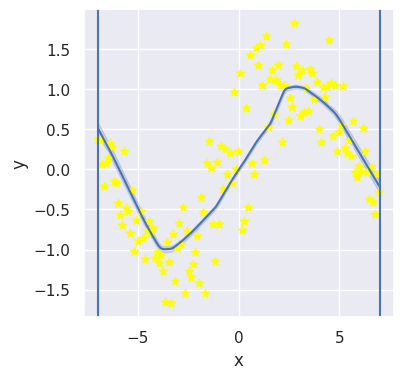

Number of data points within the 95% confidence interval: 12
Percentage of data points within the 95% confidence interval: 8.571428571428571


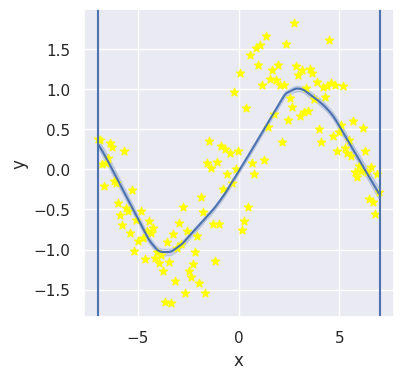

Number of data points within the 95% confidence interval: 10
Percentage of data points within the 95% confidence interval: 7.142857142857142


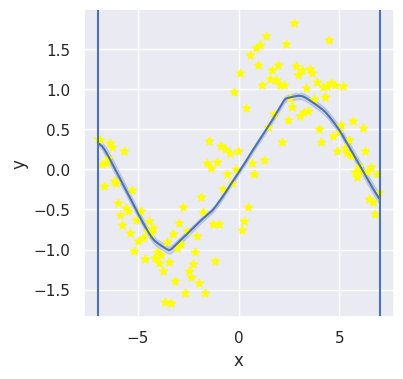

Number of data points within the 95% confidence interval: 16
Percentage of data points within the 95% confidence interval: 11.428571428571429


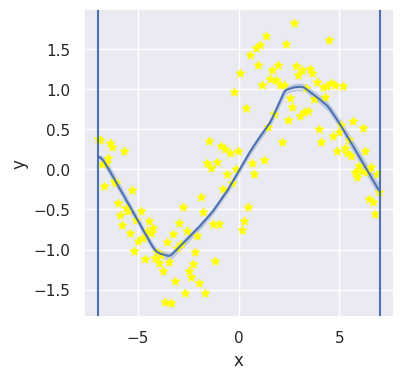

Number of data points within the 95% confidence interval: 8
Percentage of data points within the 95% confidence interval: 5.714285714285714


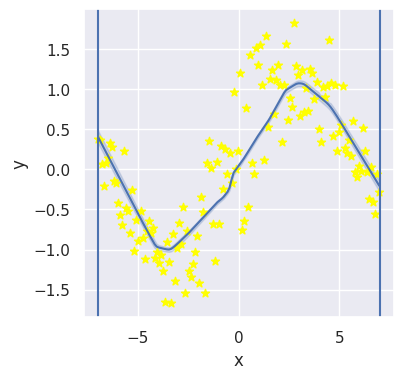

Number of data points within the 95% confidence interval: 10
Percentage of data points within the 95% confidence interval: 7.142857142857142


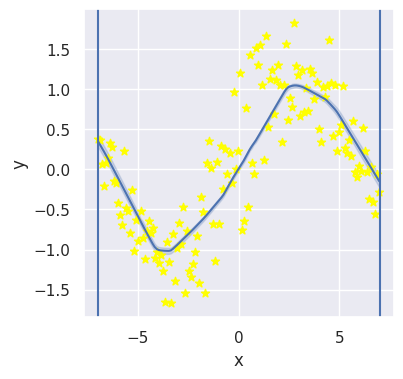

Number of data points within the 95% confidence interval: 13
Percentage of data points within the 95% confidence interval: 9.285714285714286


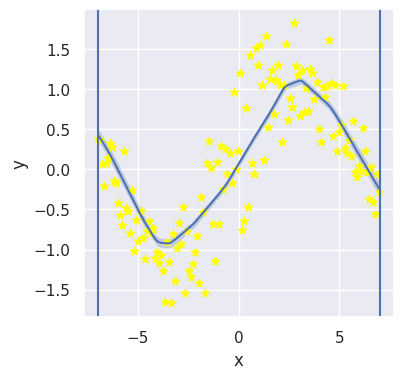

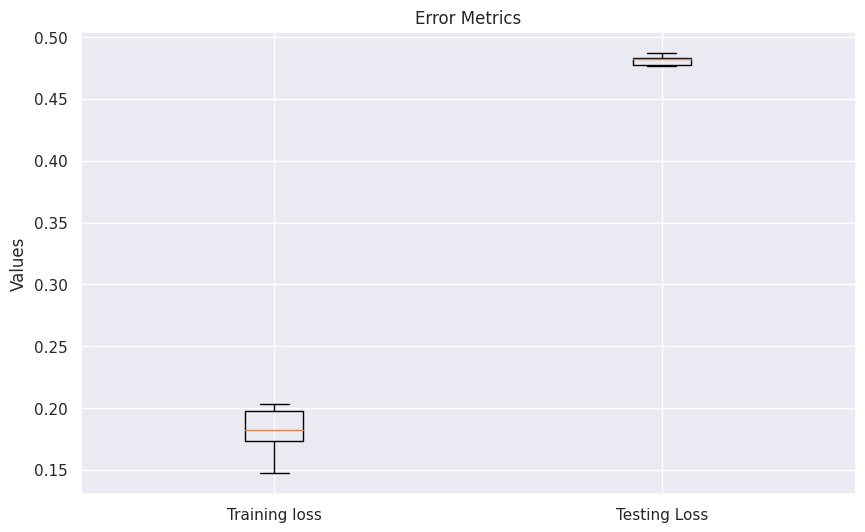

    Training Loss  Testing Loss  % of points in Confidence Interval
1        0.195745      0.478744                            6.428571
2        0.147626      0.477451                            7.142857
3        0.198336      0.483168                            9.285714
4        0.198411      0.477473                            8.571429
5        0.203405      0.484055                            8.571429
6        0.166270      0.482304                            7.142857
7        0.172527      0.483338                           11.428571
8        0.179656      0.482960                            5.714286
9        0.175493      0.476485                            7.142857
10       0.184765      0.487253                            9.285714
Mean of Gausiann Training Loss of 10 runs  0.18222339302301407
Standard Deviation of Gausiann Training Loss of 10 runs  0.01660431190247956
Mean of Gausiann Testing Loss of 10 runs  0.4813230656915241
Standard Deviation of Gausiann Testing Loss of 10 r

In [ ]:
for tst_loader,tnsor_x_test,tnsor_y_test, col, x_test,y_test,output_dir, error_metric,tst_dtast in zip(test_loaders,test_tensors_x,test_tensors_y,color,testset_x,testset_y,output_dirs,error_mets,test_datasets):
  train_losses=[]
  test_losses=[]
  percentages_count_within_ci=[]
  for i in range(10):
    net=BayesianNetwork()
    tr_loss,test_loss,model,percentage_count_within_ci = Neural_Network(net,train_loader,test_loader_vars[tst_loader],tensor_x_mapping[tnsor_x_test],tensor_y_mapping[tnsor_y_test],testset_x_mapping[x_test],testset_y_mapping[y_test],col,test_datasets_mapping[tst_dtast])
    error_metrics=tr_loss,test_loss,model,percentage_count_within_ci
    model_filename = f"{output_dir}model_{i}.pkl"
    with open(model_filename, 'wb') as file:
      pickle.dump(error_metrics, file)
    train_losses.append(tr_loss)
    test_losses.append(test_loss)

    percentages_count_within_ci.append(percentage_count_within_ci)
  # Extract numerical values from the tensors and remove grad_fn
  tr_loss_values= [tensor.item() for tensor in train_losses]
  test_loss_values=test_losses

  # Create a figure and axis
  fig, ax = plt.subplots(figsize=(10, 6))
  # Create box plots for each dataset
  box_plot_data = [tr_loss_values, test_loss_values]
  box_labels = ['Training loss', 'Testing Loss']
  ax.boxplot(box_plot_data, labels=box_labels)
  # Add labels and title
  ax.set_ylabel('Values')
  ax.set_title('Error Metrics')
  plt.savefig(f'bnn_arch_{error_metric}.png', dpi=300)
  # Show the plot
  plt.show()

  mean_gaus_train_loss = np.mean(tr_loss_values)
  std_dev_gaus_train_loss = np.std(tr_loss_values)

  mean_gaus_test_loss = np.mean(test_loss_values)
  std_dev_gaus_test_loss = np.std(test_loss_values)

  mean_percentages_count_within_ci = np.mean(percentages_count_within_ci)
  std_dev_percentages_count_within_ci = np.std(percentages_count_within_ci)

  # Create a DataFrame from the lists
  data = {
    'Training Loss': tr_loss_values,
    'Testing Loss': test_loss_values,
    '% of points in Confidence Interval':percentages_count_within_ci,
  }

  num_columns = len(data)

  column_names = ['Training Loss','Testing Loss','% of points in Confidence Interval']
  # Create a DataFrame with dynamic column names
  df = pd.DataFrame(data, columns=column_names)
  df.index += 1
  # Display the DataFrame as a table
  print(df)
  df.to_csv(f'bnn_results_{error_metric}.txt', index=True)
  print('Mean of Gausiann Training Loss of 10 runs ', mean_gaus_train_loss)
  print('Standard Deviation of Gausiann Training Loss of 10 runs ' , std_dev_gaus_train_loss )

  print('Mean of Gausiann Testing Loss of 10 runs ',mean_gaus_test_loss )
  print('Standard Deviation of Gausiann Testing Loss of 10 runs ',std_dev_gaus_test_loss)

  print('Mean of percentage of 95% conf interval for 10 runs in data',mean_percentages_count_within_ci)
  print('Standard Deviation of percentage of 95% conf interval for 10 runs in data ' , std_dev_percentages_count_within_ci)

  # File path
  file_path = f'bnn_summary_{error_metric}.txt'

  # Open the file in write mode
  with open(file_path, 'w') as file:
    # Write the results to the file
    file.write('Mean of Gaussian Training Loss of 10 runs: {}\n'.format(mean_gaus_train_loss))
    file.write('Standard Deviation of Gaussian Training Loss of 10 runs: {}\n\n'.format(std_dev_gaus_train_loss))

    file.write('Mean of Gaussian Testing Loss of 10 runs: {}\n'.format(mean_gaus_test_loss))
    file.write('Standard Deviation of Gaussian Testing Loss of 10 runs: {}\n\n'.format(std_dev_gaus_test_loss))

    file.write('Mean of percentage of 95% conf interval for 10 runs in data {}\n'.format(mean_percentages_count_within_ci))
    file.write('Standard Deviation of percentage of 95% conf interval for 10 runs in data {}\n\n'.format(std_dev_percentages_count_within_ci))

  # Print a message indicating the file has been saved
  print(f'Results summary saved to {file_path}')
